# SVM and the classification of a non-linear dataset

### Definition of a hyperplane and SVM classifier:

For a linearly separable dataset having n features (thereby needing n dimensions for representation), a hyperplane is basically an (n – 1) dimensional subspace used for separating the dataset into two sets, each set containing data points belonging to a different class. For example, for a dataset having two features X and Y (therefore lying in a 2-dimensional space), the separating hyperplane is a line (a 1-dimensional subspace). Similarly, for a dataset having 3-dimensions, we have a 2-dimensional separating hyperplane, and so on.
In machine learning, Support Vector Machine (SVM) is a non-probabilistic, linear, binary classifier used for classifying data by learning a hyperplane separating the data.

### Classifying a non-linearly separable dataset using SVM – a linear classifier:

As mentioned above SVM is a linear classifier which learns an (n – 1)-dimensional classifier for classification of data into two classes. However, it can be used for classifying a non-linear dataset. This can be done by projecting the dataset into a higher dimension in which it is linearly separable!

Let's consider a non-linear dataset

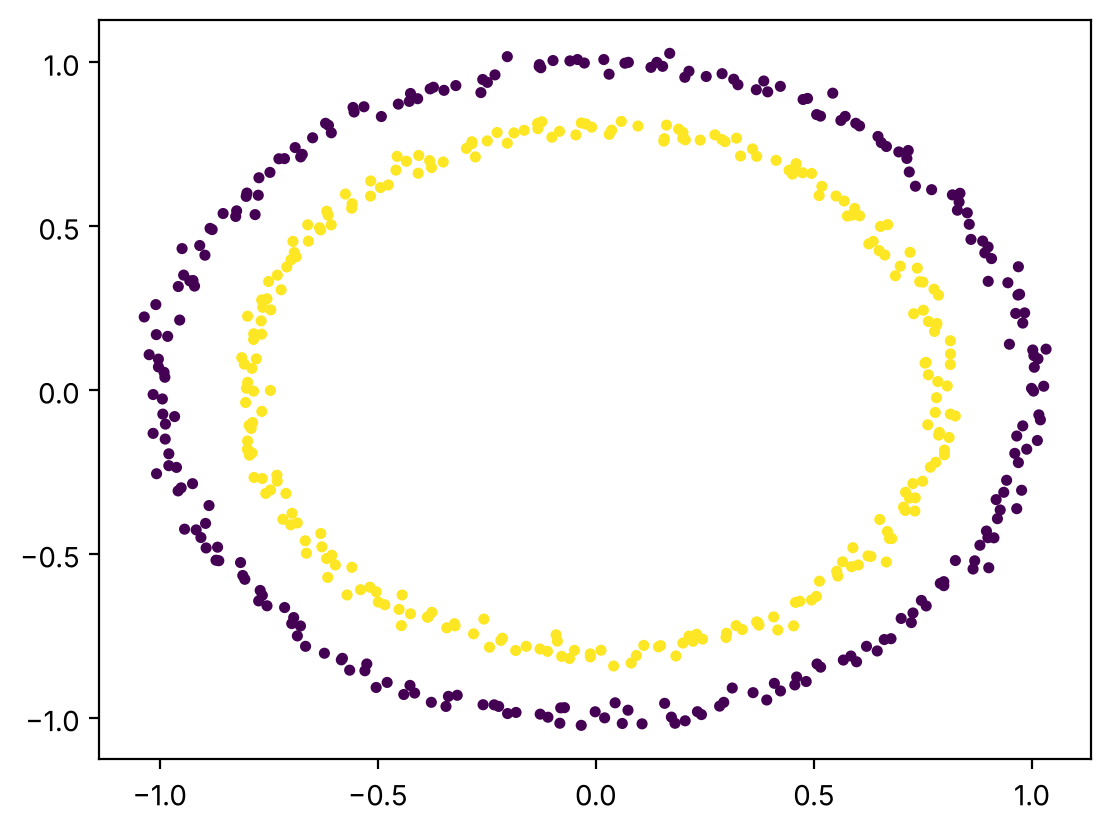

In [1]:
# importing libraries
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_circles
from mpl_toolkits.mplot3d import Axes3D
  
# generating data
np.random.seed(0)   # reproductibilité
X, Y = make_circles(n_samples = 500, noise = 0.02, random_state = 0)
  
# visualizing data
plt.scatter(X[:, 0], X[:, 1], c = Y, marker = '.')
plt.show()

The dataset is clearly a non-linear dataset and consists of two features (say, X and Y).

In order to use SVM for classifying this data, introduce another feature Z = X2 + Y2 into the dataset. Thus, projecting the 2-dimensional data into 3-dimensional space. The first dimension representing the feature X, second representing Y and third representing Z (which, mathematically, is equal to the radius of the circle of which the point (x, y) is a part of). Now, clearly, for the data shown above, the ‘yellow’ data points belong to a circle of smaller radius and the ‘purple’ data points belong to a circle of larger radius. Thus, the data becomes linearly separable along the Z-axis.

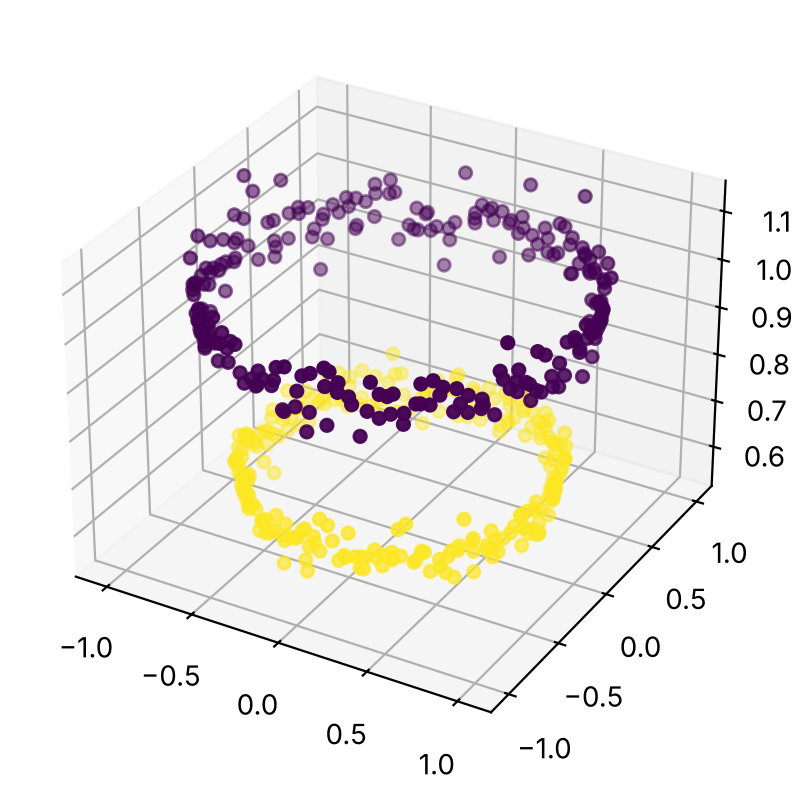

In [2]:
# adding a new dimension to X
X1 = X[:, 0].reshape((-1, 1))
X2 = X[:, 1].reshape((-1, 1))
X3 = (X1**2 + X2**2)
X = np.hstack((X, X3))
  
# visualizing data in higher dimension
fig = plt.figure()
axes = fig.add_subplot(111, projection = '3d')
axes.scatter(X1, X2, X1**2 + X2**2, c = Y, depthshade = True)
plt.show()

Now, we can use SVM (or, for that matter, any other linear classifier) to learn a 2-dimensional separating hyperplane. This is how the hyperplane would look like:

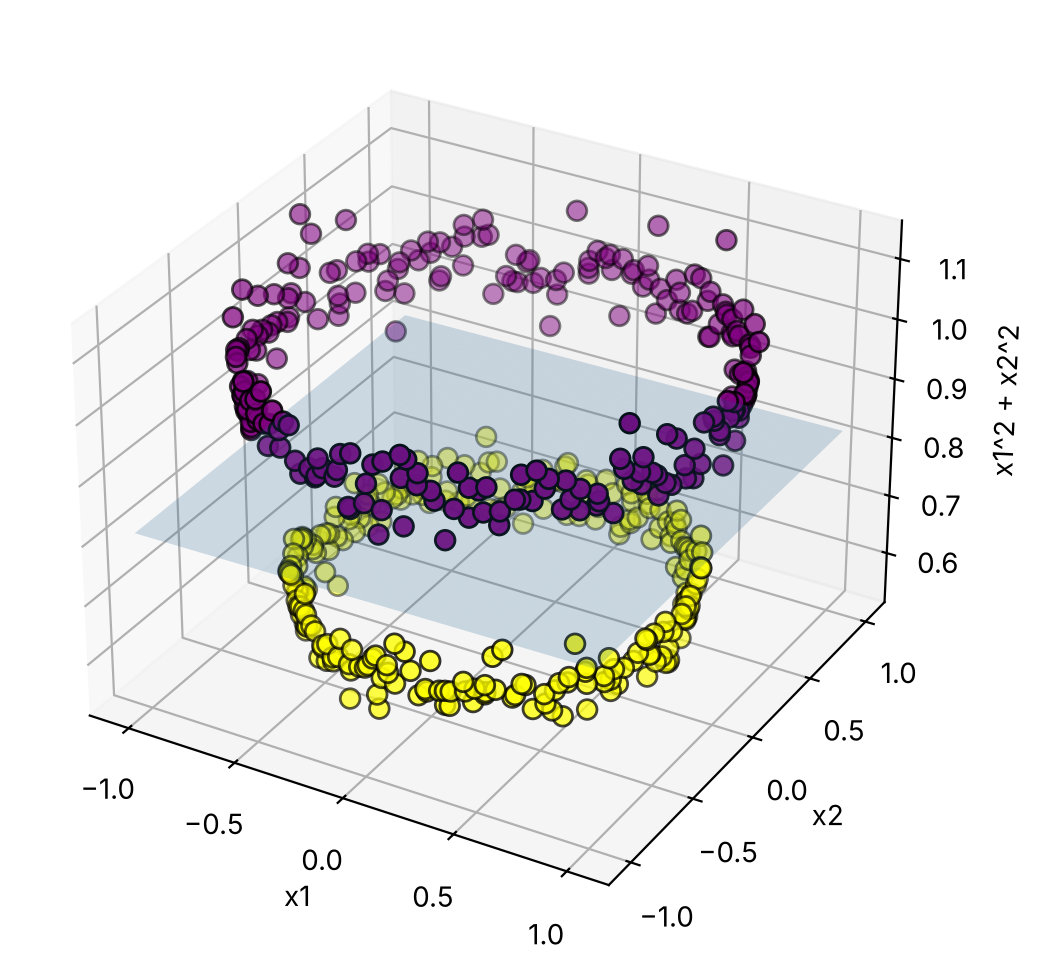

In [3]:
from sklearn import svm
from mpl_toolkits.mplot3d import Axes3D
from matplotlib.colors import ListedColormap

# 3D mapped data
Z = np.c_[X1, X2, X1**2 + X2**2]

svc = svm.SVC(kernel='linear')
svc.fit(Z, Y)

w = svc.coef_[0]
b = svc.intercept_[0]

# grid for the plane
x1_grid = np.linspace(X1.min(), X1.max(), 50)
x2_grid = np.linspace(X2.min(), X2.max(), 50)
x1_mesh, x2_mesh = np.meshgrid(x1_grid, x2_grid)
x3_mesh = -(w[0] * x1_mesh + w[1] * x2_mesh + b) / w[2]

# plot
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection='3d')

# yellow and purple colormap
cmap = ListedColormap(['purple','yellow'])

ax.scatter(X1, X2, X1**2 + X2**2, c=Y, cmap=cmap, s=50, edgecolor='k')

# separating plane
ax.plot_surface(x1_mesh, x2_mesh, x3_mesh, alpha=0.2)

ax.set_xlabel('x1')
ax.set_ylabel('x2')
ax.set_zlabel('x1^2 + x2^2')

plt.show()

<b>What do you conclude ?<b/>

In [4]:
from sklearn.metrics import accuracy_score
# 1) SVM linéaire sur les données d'origine (2D) : x1, x2
svc2d = svm.SVC(kernel='linear').fit(X[:, :2], Y)
print('SVM linéaire en 2D (x1, x2)         : accuracy = %.3f' % svc2d.score(X[:, :2], Y))
# 2) SVM linéaire après ajout de la 3e dimension z = x1^2 + x2^2
print('SVM linéaire en 3D (x1, x2, x1²+x2²) : accuracy = %.3f' % svc.score(Z, Y))
print('Rayons moyens : classe 0 = %.2f, classe 1 = %.2f' % (np.sqrt((X[Y==0,0]**2+X[Y==0,1]**2)).mean(), np.sqrt((X[Y==1,0]**2+X[Y==1,1]**2)).mean()))
print('Plan séparant : w = %s, b = %.3f' % (np.round(w, 2), b))

SVM linéaire en 2D (x1, x2)         : accuracy = 0.502
SVM linéaire en 3D (x1, x2, x1²+x2²) : accuracy = 1.000
Rayons moyens : classe 0 = 1.00, classe 1 = 0.80
Plan séparant : w = [ 0.03  0.01 -7.17], b = 5.863


#### Conclusion

- Les deux cercles ne sont **pas linéairement séparables en 2D** : le SVM linéaire sur (x₁, x₂) fait **≈ 50 %** (le hasard).
- En ajoutant la variable **z = x₁² + x₂²** (le carré du rayon), les points du petit cercle (rayon 0.8, z ≈ 0.64) et du grand cercle (rayon 1, z ≈ 1) se retrouvent à des **hauteurs différentes** : un simple plan horizontal les sépare, et le SVM linéaire atteint **100 %**. On le voit dans le vecteur normal du plan : `w ≈ [0.03, 0.01, −7.17]`, presque entièrement porté par la 3ᵉ coordonnée.
- **Conclusion** : un classifieur linéaire peut résoudre un problème non linéaire à condition de projeter les données dans un espace de dimension plus grande où elles deviennent linéairement séparables. C'est l'idée de l'**astuce du noyau**, qui évite de calculer explicitement cette projection.

### Activity

In machine learning, a trick known as “kernel trick” is used to learn a linear classifier to classify a non-linear dataset. It transforms the linearly inseparable data into a linearly separable one by projecting it into a higher dimension. A kernel function is applied on each data instance to map the original non-linear data points into some higher dimensional space in which they become linearly separable.
- Use the kernel trick to directly classifiy the circles dataset. Try different kernels (Gaussian Radial Basis Function Kernel, Sigmoid Kernel, Polynomial Kernel )

In [5]:
import pandas as pd
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from matplotlib.colors import ListedColormap

X2 = X[:, :2]                                   # données d'origine (2D)
Xtr, Xte, ytr, yte = train_test_split(X2, Y, test_size=0.3, random_state=0, stratify=Y)
cv = StratifiedKFold(5, shuffle=True, random_state=0)

kernels = {
 'linear'                    : svm.SVC(kernel='linear'),
 'poly (degré 2)'            : svm.SVC(kernel='poly', degree=2),
 'poly (degré 3)'            : svm.SVC(kernel='poly', degree=3),
 'poly (degré 3, coef0=1)'   : svm.SVC(kernel='poly', degree=3, coef0=1),
 'rbf (gamma=scale)'         : svm.SVC(kernel='rbf'),
 'rbf (gamma=0.1)'           : svm.SVC(kernel='rbf', gamma=0.1),
 'rbf (gamma=10)'            : svm.SVC(kernel='rbf', gamma=10),
 'sigmoid'                   : svm.SVC(kernel='sigmoid'),
}
rows = []
for name, m in kernels.items():
    m.fit(Xtr, ytr)
    rows.append(dict(noyau=name, train=m.score(Xtr, ytr), test=m.score(Xte, yte),
                     CV5=cross_val_score(m, X2, Y, cv=cv).mean(), vecteurs_supports=int(m.n_support_.sum())))
res = pd.DataFrame(rows).set_index('noyau')
display((res.assign(vecteurs_supports=res.vecteurs_supports)).round(3))

,train,test,CV5,vecteurs_supports
noyau,,,,
linear,0.503,0.507,0.464,346
poly (degré 2),1.000,1.000,1.000,70
poly (degré 3),0.543,0.513,0.476,343
"poly (degré 3, coef0=1)",1.000,1.000,1.000,33
rbf (gamma=scale),1.000,1.000,1.000,149
rbf (gamma=0.1),0.603,0.567,0.568,350
rbf (gamma=10),1.000,1.000,1.000,100
sigmoid,0.500,0.500,0.528,197


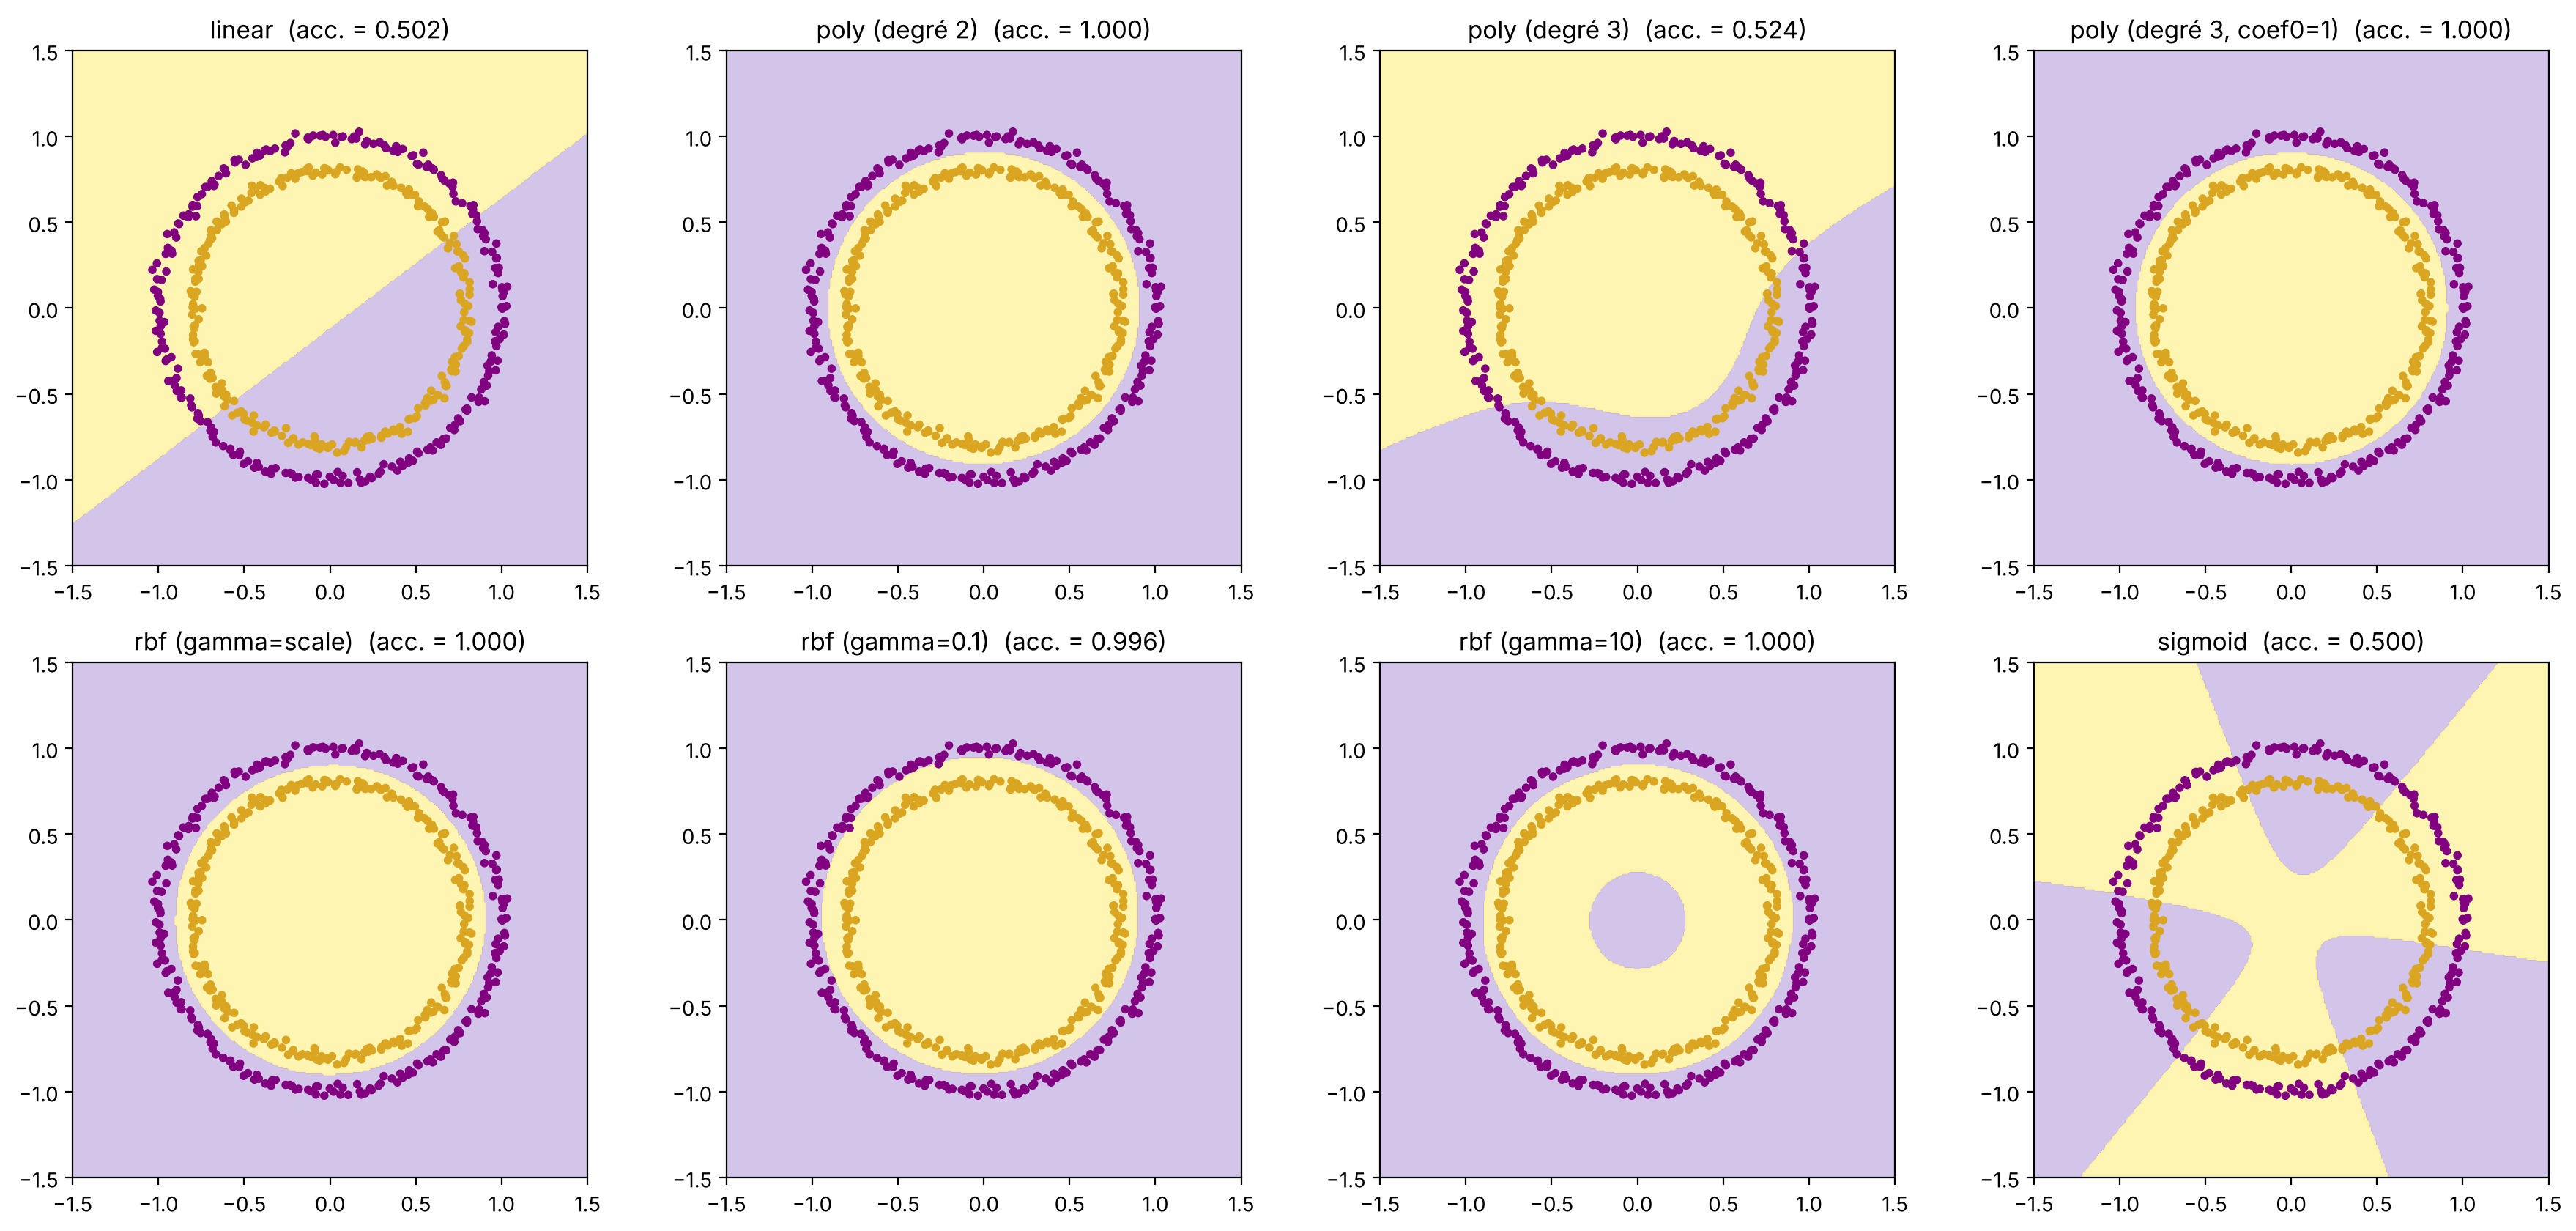

In [6]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8.5))
gx, gy = np.meshgrid(np.linspace(-1.5, 1.5, 300), np.linspace(-1.5, 1.5, 300))
for ax, (name, m) in zip(axes.ravel(), kernels.items()):
    m.fit(X2, Y)
    ax.contourf(gx, gy, m.predict(np.c_[gx.ravel(), gy.ravel()]).reshape(gx.shape), cmap=ListedColormap(['#c9b6e4', '#fff3a0']), alpha=.8)
    ax.scatter(X2[:, 0], X2[:, 1], c=Y, cmap=ListedColormap(['purple', 'goldenrod']), s=10)
    ax.set_title('%s  (acc. = %.3f)' % (name, m.score(X2, Y))); ax.set_aspect('equal')
plt.tight_layout(); plt.show()

#### Remarques

- **Noyaux qui réussissent (100 % en train, test et validation croisée)** : `poly` de degré 2, `rbf` (`gamma='scale'` et `gamma=10`) et `poly` de degré 3 avec `coef0=1`. Ils classent directement les données 2D, **sans ajouter explicitement la variable z** : le noyau calcule implicitement le produit scalaire dans l'espace de grande dimension.
- **`poly` degré 2** s'en sort avec seulement 70 vecteurs supports, car le noyau quadratique contient exactement le terme x₁² + x₂² utilisé dans l'exemple. Le RBF utilise plus de vecteurs supports (149 pour `gamma='scale'`, 100 pour `gamma=10`) mais fonctionne aussi bien.
- **Noyaux qui échouent** : le noyau **linéaire** (≈ 50 %, comme attendu) ; le noyau **sigmoïde** (50 %) ; le noyau **`poly` de degré 3 avec `coef0=0`** (≈ 51 %) : ce polynôme *homogène* ne contient que des termes de degré 3, donc impairs (changer (x₁, x₂) en (−x₁, −x₂) change leur signe), alors que les deux cercles sont symétriques par rapport à l'origine. Avec `coef0=1`, les termes de degré inférieur (dont x₁² + x₂²) sont inclus et le degré 3 réussit (100 %).
- **Rôle de `gamma` pour le RBF** : `gamma=0.1` est trop petit (noyau trop « lisse », frontière presque linéaire) et sous-apprend (≈ 57–60 %) ; `gamma=10` ou `scale` conviennent. Un `gamma` trop grand surapprendrait sur des données plus bruitées.
- **Conclusion** : le choix du noyau (et de ses hyper-paramètres) doit être adapté à la **structure** des données ; ici, un polynôme de degré 2 ou un RBF conviennent, alors que le linéaire et le sigmoïde non.